# Práctica 1 — Aplicaciones colaborativas para Inteligencia Artificial
**Estudiante:** Hamilton Mauricio Valer Campos  
**Programa:** Maestría en Inteligencia Artificial Aplicada — UTPL  
**Módulo:** Herramientas para Inteligencia Artificial

## Caso: análisis exploratorio de condiciones operativas de maquinaria industrial

**Propósito.** Cargar un CSV en Pandas, construir **cuatro columnas derivadas**, generar **dos visualizaciones** y ejecutar el mismo notebook en un entorno **local (JupyterLab)** y **en la nube (Google Colab)**.

**Naturaleza de los datos:** conjunto **sintético** generado exclusivamente para esta práctica. No se trata de mediciones reales, fallas verificadas ni de un modelo predictivo entrenado. Los umbrales son **supuestos didácticos**, no criterios de intervención certificados.

## 1. Bibliotecas y archivo de entrada
Se emplean **Pandas** para tablas y transformaciones; **NumPy** para operaciones numéricas; y **Matplotlib** para gráficos.

El archivo de entrada contiene 180 observaciones con fecha, identificador de equipo, temperatura, vibración, velocidad y horas de operación.

**En JupyterLab:** coloca el CSV en la misma carpeta que este `.ipynb`.  
**En Colab:** sube ambos archivos a la sesión. Si no se encuentra el CSV, la siguiente celda ofrece subirlo manualmente.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print('Python:', sys.version.split()[0])
print('Pandas:', pd.__version__)
print('Intérprete:', sys.executable)

Python: 3.10.8
Pandas: 2.3.3
Intérprete: D:\MAURICIO\Escritorio\clases-python\env_pandas\Scripts\python.exe


In [2]:
archivo = Path('datos_sensores_industriales.csv')
if not archivo.exists():
    try:
        from google.colab import files
        print('Sube el archivo datos_sensores_industriales.csv:')
        files.upload()
    except ImportError:
        raise FileNotFoundError('Coloca el CSV junto al notebook antes de continuar.')

df = pd.read_csv(archivo, parse_dates=['fecha'])
print('Dimensiones originales:', df.shape)
display(df.head())

Dimensiones originales: (180, 7)


,registro,fecha,equipo,temperatura_c,vibracion_mm_s,velocidad_rpm,horas_operacion
0,R001,2026-10-01 00:00:00,MOTOR-01,60.8,2.77,1405,500
1,R002,2026-10-01 03:00:00,BOMBA-02,54.7,2.91,1776,537
2,R003,2026-10-01 06:00:00,VENT-03,49.9,1.59,1200,574
3,R004,2026-10-01 09:00:00,MOTOR-01,42.1,1.44,1416,611
4,R005,2026-10-01 12:00:00,BOMBA-02,56.4,0.70,1763,648


## 2. Comprobación de calidad de datos
Antes de realizar cálculos, comprobamos los tipos de datos, los valores faltantes, las observaciones duplicadas y los rangos básicos.

In [3]:
print('Tipos de datos:')
print(df.dtypes)
print('\nValores faltantes:')
print(df.isna().sum())
print('\nDuplicados por registro:', df['registro'].duplicated().sum())
assert len(df) > 0, 'El archivo no contiene observaciones.'
assert df['registro'].is_unique, 'Existen identificadores duplicados.'
assert df[['temperatura_c','vibracion_mm_s','horas_operacion']].notna().all().all()
assert (df[['temperatura_c','vibracion_mm_s','horas_operacion']] >= 0).all().all()


Tipos de datos:
registro                   object
fecha              datetime64[ns]
equipo                     object
temperatura_c             float64
vibracion_mm_s            float64
velocidad_rpm               int64
horas_operacion             int64
dtype: object

Valores faltantes:
registro           0
fecha              0
equipo             0
temperatura_c      0
vibracion_mm_s     0
velocidad_rpm      0
horas_operacion    0
dtype: int64

Duplicados por registro: 0


## 3. Cuatro columnas derivadas
**Supuestos educativos del ejercicio:** temperatura crítica si `temperatura_c >= 75`; vibración baja si es menor de 3, media entre 3 y menos de 6, y alta desde 6 mm/s. Se construye un índice de condición de **0 (menor señal de alerta)** a **100 (mayor señal de alerta)** con pesos ilustrativos: 50 % temperatura y 50 % vibración. Este índice **no es una métrica industrial validada**.

La prioridad de inspección se asigna como *Alta* si hay temperatura crítica o vibración alta; *Media* si la vibración es media; y *Baja* en el resto.

In [4]:
# Columna 1: temperatura crítica (booleano)
df['temperatura_critica'] = df['temperatura_c'] >= 75

# Columna 2: categoría de vibración
df['nivel_vibracion'] = pd.cut(
    df['vibracion_mm_s'], bins=[-np.inf, 3, 6, np.inf],
    labels=['Bajo', 'Medio', 'Alto'], right=False
)

# Columna 3: índice sintético educativo entre 0 y 100
p_temp = ((df['temperatura_c'] - 40) / (90 - 40)).clip(0, 1)
p_vib = ((df['vibracion_mm_s'] - 1) / (10 - 1)).clip(0, 1)
df['indice_condicion'] = (100 * (0.5*p_temp + 0.5*p_vib)).round(1)

# Columna 4: prioridad educativa de inspección
alta = df['temperatura_critica'] | df['nivel_vibracion'].eq('Alto')
media = df['nivel_vibracion'].eq('Medio')
df['prioridad_inspeccion'] = np.select([alta, media], ['Alta', 'Media'], default='Baja')

print('Dimensiones tras agregar cuatro columnas:', df.shape)
display(df.head(10))

Dimensiones tras agregar cuatro columnas: (180, 11)


,registro,fecha,equipo,temperatura_c,vibracion_mm_s,velocidad_rpm,horas_operacion,temperatura_critica,nivel_vibracion,indice_condicion,prioridad_inspeccion
0,R001,2026-10-01 00:00:00,MOTOR-01,60.8,2.77,1405,500,False,Bajo,30.6,Baja
1,R002,2026-10-01 03:00:00,BOMBA-02,54.7,2.91,1776,537,False,Bajo,25.3,Baja
2,R003,2026-10-01 06:00:00,VENT-03,49.9,1.59,1200,574,False,Bajo,13.2,Baja
3,R004,2026-10-01 09:00:00,MOTOR-01,42.1,1.44,1416,611,False,Bajo,4.5,Baja
4,R005,2026-10-01 12:00:00,BOMBA-02,56.4,0.70,1763,648,False,Bajo,16.4,Baja
5,R006,2026-10-01 15:00:00,VENT-03,71.8,4.56,1235,685,False,Medio,51.6,Media
6,R007,2026-10-01 18:00:00,MOTOR-01,38.0,2.53,1457,722,False,Bajo,8.5,Baja
7,R008,2026-10-01 21:00:00,BOMBA-02,44.1,2.48,1788,759,False,Bajo,12.3,Baja
8,R009,2026-10-02 00:00:00,VENT-03,80.1,2.30,1242,796,True,Bajo,47.3,Alta
9,R010,2026-10-02 03:00:00,MOTOR-01,38.0,1.26,1479,833,False,Bajo,1.4,Baja


## 4. Análisis descriptivo
Se resumen los registros y la frecuencia de prioridades propuestas por las reglas didácticas.

In [5]:
display(df[['temperatura_c','vibracion_mm_s','velocidad_rpm','horas_operacion','indice_condicion']].describe().round(2))
print('Prioridades de inspección:')
print(df['prioridad_inspeccion'].value_counts())
print('Registros de temperatura crítica:', int(df['temperatura_critica'].sum()))

,temperatura_c,vibracion_mm_s,velocidad_rpm,horas_operacion,indice_condicion
count,180.00,180.00,180.00,180.00,180.00
mean,62.76,3.42,1474.23,3811.50,36.30
std,10.39,1.61,235.72,1927.91,15.25
min,38.00,0.70,1095.00,500.00,1.40
25%,55.30,2.45,1216.00,2155.75,25.78
50%,63.30,3.30,1477.00,3811.50,37.85
75%,70.45,4.28,1730.00,5467.25,47.30
max,84.80,8.44,1826.00,7123.00,71.20


Prioridades de inspección:
prioridad_inspeccion
Media    78
Baja     69
Alta     33
Name: count, dtype: int64
Registros de temperatura crítica: 23


## 5. Visualización 1 — Temperatura por registro
La línea presenta la evolución de la temperatura por orden cronológico; la línea horizontal marca el **umbral ilustrativo de 75 °C**. No representa una alarma de fabricante.

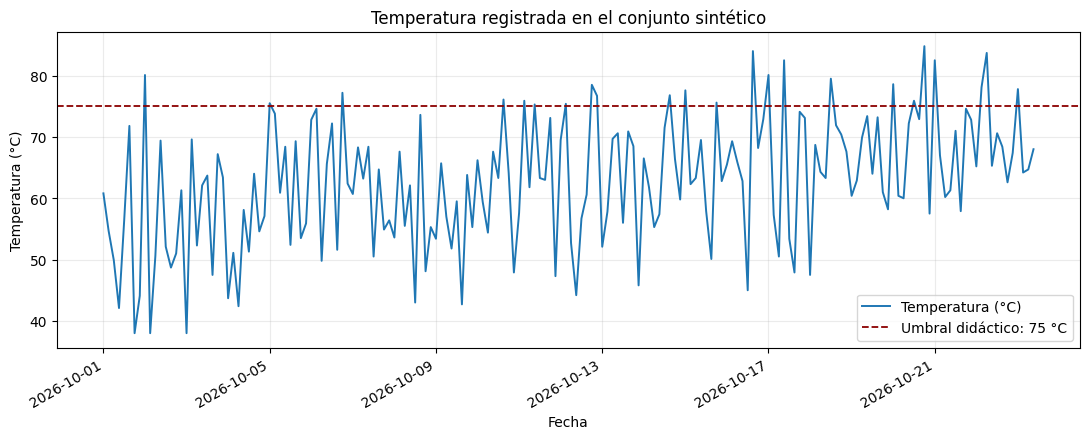

In [6]:
fig, ax = plt.subplots(figsize=(11,4.5))
orden = df.sort_values('fecha')
ax.plot(orden['fecha'], orden['temperatura_c'], linewidth=1.4, label='Temperatura (°C)')
ax.axhline(75, color='darkred', linestyle='--', linewidth=1.3, label='Umbral didáctico: 75 °C')
ax.set(title='Temperatura registrada en el conjunto sintético', xlabel='Fecha', ylabel='Temperatura (°C)')
ax.grid(alpha=0.25)
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## 6. Visualización 2 — Distribución de niveles de vibración
El gráfico de barras permite observar la frecuencia de los niveles *Bajo*, *Medio* y *Alto*, definidos con fines de aprendizaje.

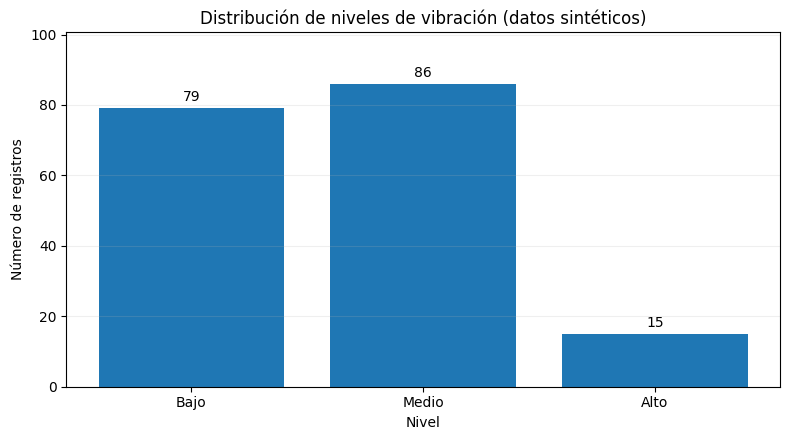

In [7]:
conteo = df['nivel_vibracion'].value_counts().reindex(['Bajo','Medio','Alto'], fill_value=0)
fig, ax = plt.subplots(figsize=(8,4.5))
bars = ax.bar(conteo.index.astype(str), conteo.values)
for bar in bars:
    ax.annotate(str(int(bar.get_height())), (bar.get_x()+bar.get_width()/2, bar.get_height()),
                ha='center', va='bottom', xytext=(0,3), textcoords='offset points')
ax.set(title='Distribución de niveles de vibración (datos sintéticos)', xlabel='Nivel', ylabel='Número de registros')
ax.set_ylim(0, conteo.max()*1.17)
ax.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.show()

## 7. Verificación y conclusiones
**Verificaciones técnicas:** dataset estructurado, cuatro variables adicionales y dos gráficos construidos con bibliotecas adecuadas.

**Conclusiones:** (1) Pandas facilita transformar mediciones tabulares en indicadores legibles; (2) Matplotlib permite comunicar tendencias y frecuencias de manera visual; (3) la misma secuencia puede reproducirse en JupyterLab y Google Colab con el archivo de datos correspondiente. **Limitación:** los datos y umbrales son sintéticos; no se debe inferir capacidad real de predicción de fallas.

### Evidencias de ambientes
- **Local:** ejecutar el notebook en JupyterLab y guardar una captura con la ruta de `sys.executable`.
- **Nube:** ejecutar el mismo notebook en Colab y guardar una captura donde se observe la ejecución.
- **Entrega:** compartir el notebook y CSV, y exportar el notebook ejecutado a PDF o compartir un enlace público, según lo indicado por el docente.

### Bibliografía básica
- Pandas Development Team. (s. f.). *User guide*. https://pandas.pydata.org/docs/user_guide/index.html
- NumPy Developers. (s. f.). *NumPy documentation*. https://numpy.org/doc/stable/
- Matplotlib Development Team. (s. f.). *Matplotlib documentation*. https://matplotlib.org/stable/
- Project Jupyter. (s. f.). *JupyterLab documentation*. https://jupyterlab.readthedocs.io/en/stable/
- Google. (s. f.). *Colaboratory*. https://colab.research.google.com/